In [1]:
import tensorflow as tf

from matplotlib import pyplot as plt
from silx.io.dictdump import h5todict

In [2]:
cpu = tf.config.list_physical_devices("CPU")[0]
tf.config.set_visible_devices(cpu)

In [3]:
path_to_model = "./saving/epd/SavedModel/"

In [4]:
model = tf.keras.models.load_model(path_to_model)

In [5]:
path_to_data = "./data/test.hdf5"
case = 2

In [6]:
data = h5todict(path_to_data)["case_"+str(case).zfill(3)]

In [7]:
x = [data[k] for k in ("node_attr", "edge_attr")]
y = data["target"]
n = len(y)

In [17]:
autoregressive = False

In [18]:
if autoregressive:
    x0 = tf.nest.map_structure(lambda z: z[0:1], x)
    y_pred = [model(x0)]
    for i in range(n-1):
        xi = [y_pred[-1], x0[1]]
        y_pred.append(model(xi))
else:
    y_pred = []
    for i in range(n):
        xi = tf.nest.map_structure(lambda z: z[i:i+1], x)
        y_pred.append(model(xi))
y_pred = tf.concat(y_pred, axis=0).numpy()

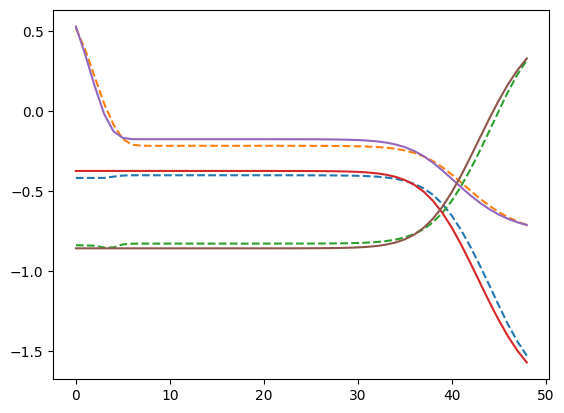

In [19]:
plt.plot(y_pred.squeeze(), '--')
plt.plot(y.squeeze(), '-')